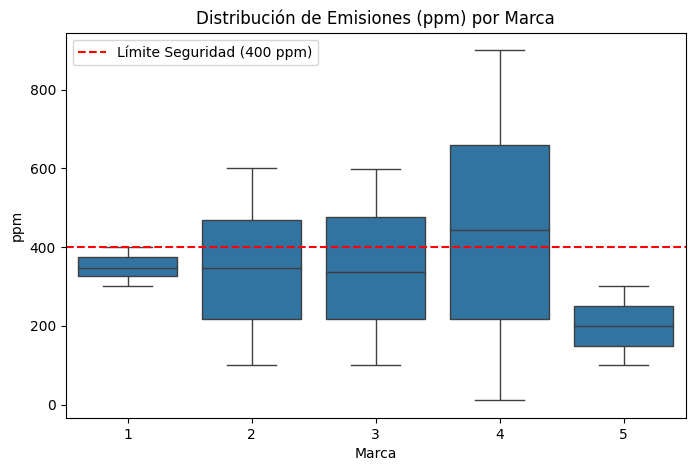

--- Estadísticas de ppm ---
       count        mean         std    min     25%    50%    75%    max
Marca                                                                   
1      705.0  349.669504   28.945138  300.0  326.00  348.0  374.0  400.0
2      711.0  346.390999  147.030692  101.0  216.50  348.0  468.5  600.0
3      734.0  342.099455  145.853810  100.0  217.25  335.5  475.5  599.0
4      773.0  446.439845  253.832154   11.0  218.00  443.0  658.0  900.0
5      740.0  198.994595   58.646806  100.0  148.00  199.0  250.0  300.0

--- % Cumplimiento de Potencia ---
Marca
1    81.702128
2    67.510549
3    26.294278
4    23.673997
5    81.081081
Name: potencia_ok, dtype: float64

--- IC Marca 5 ---
Media Potencia: (2.7561, 2.7761) kW
Varianza Potencia: (0.0173, 0.0212) kW^2
Proporción de Emisión Segura: (0.9950, 1.0000)

--- Prueba Varianzas M3 vs M4 ---
F-stat: 0.4695, p-value: 1.77e-24

--- Prueba Hipótesis Fabricante ---
p-value: 3.13e-72


In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar la base de datos
df = pd.read_excel("BD Proyecto de Aula DEF 2026-2.xlsx").dropna(subset=['Marca', 'ppm', 'Potencia'])
df['Marca'] = df['Marca'].astype(int)

# a) Boxplot de ppm
plt.figure(figsize=(8,5))
sns.boxplot(x='Marca', y='ppm', data=df)
plt.axhline(y=400, color='r', linestyle='--', label='Límite Seguridad (400 ppm)')
plt.title('Distribución de Emisiones (ppm) por Marca')
plt.legend()
plt.show()

print("--- Estadísticas de ppm ---")
print(df.groupby('Marca')['ppm'].describe())

# b) Cumplimiento de potencia nominal (2.7 ± 0.22 kW -> 2.48 a 2.92 kW)
df['potencia_ok'] = (df['Potencia'] >= 2.48) & (df['Potencia'] <= 2.92)
print("\n--- % Cumplimiento de Potencia ---")
print(df.groupby('Marca')['potencia_ok'].mean() * 100)

# d) Intervalos para la Marca con mejor desempeño (Marca 5)
df_m5 = df[df['Marca'] == 5]
n = len(df_m5)

# IC Media Potencia
mean_pot = df_m5['Potencia'].mean()
std_pot = df_m5['Potencia'].std(ddof=1)
error_m = stats.t.ppf(0.975, n-1) * (std_pot / np.sqrt(n))
print(f"\n--- IC Marca 5 ---")
print(f"Media Potencia: ({mean_pot - error_m:.4f}, {mean_pot + error_m:.4f}) kW")

# IC Varianza Potencia
var_pot = df_m5['Potencia'].var(ddof=1)
chi2_inf = stats.chi2.ppf(0.975, n-1)
chi2_sup = stats.chi2.ppf(0.025, n-1)
print(f"Varianza Potencia: ({(n-1)*var_pot / chi2_inf:.4f}, {(n-1)*var_pot / chi2_sup:.4f}) kW^2")

# IC Proporción ppm <= 400 (Exacto Binomial porque el 100% cumple)
ic_prop_inf = stats.beta.ppf(0.025, n, 1)
print(f"Proporción de Emisión Segura: ({ic_prop_inf:.4f}, 1.0000)")

# e) Prueba de varianzas (F-test) Marcas 3 y 4
pot3 = df[df['Marca'] == 3]['Potencia']
pot4 = df[df['Marca'] == 4]['Potencia']
f_stat = pot3.var(ddof=1) / pot4.var(ddof=1)
p_val_f = 2 * min(stats.f.cdf(f_stat, len(pot3)-1, len(pot4)-1), 1 - stats.f.cdf(f_stat, len(pot3)-1, len(pot4)-1))
print(f"\n--- Prueba Varianzas M3 vs M4 ---")
print(f"F-stat: {f_stat:.4f}, p-value: {p_val_f:.2e}")

# f) Prueba de Hipótesis Proporción Marca 5 (p0 = 0.80)
binom_test = stats.binomtest(n, n, 0.80, alternative='two-sided')
print(f"\n--- Prueba Hipótesis Fabricante ---")
print(f"p-value: {binom_test.pvalue:.2e}")